In [1]:
import sys, platform
ON_LINUXONE = platform.machine() == "s390x"
DATA_PATH = ("/home/ibm-user/transactions_history.csv" if ON_LINUXONE
             else "transactions_history.csv")
SEED = 42
TRAIN_END_YEAR = 2015         # train: up to 2015
VALID_YEARS = (2016, 2017)    # validation: compare models here
TEST_YEARS = (2018, 2019)     # test: use once in step 22

import pandas as pd
import numpy as np
import sklearn
import xgboost
import tensorflow as tf
import keras

print("Machine:", platform.machine(), "| Python:", sys.version.split()[0])

Machine: s390x | Python: 3.12.15


In [2]:
# 1. Load data
df = pd.read_csv(DATA_PATH)

# 2. Clean Amount: "$134.09" -> 134.09
df['Amount_num'] = df['Amount'].astype(str).str.replace('$', '', regex=False).astype(float)

# 3. Clean 'Is Fraud?' -> 1 / 0
# Bypass the object dtype check to support Pandas 3.x StringDtype
df['is_fraud'] = (df['Is Fraud?'].astype(str).str.strip().str.lower() == 'yes').astype(int)

# 4. Create single timestamp 'ts'
time_split = df['Time'].astype(str).str.split(':', expand=True)
df['hour'] = time_split[0].astype(int)
df['minute'] = time_split[1].astype(int)

df['ts'] = pd.to_datetime(dict(
    year=df['Year'],
    month=df['Month'],
    day=df['Day'],
    hour=df['hour'],
    minute=df['minute']
))

# 5. Sort chronologically
df = df.sort_values(by=['User', 'Card', 'ts']).reset_index(drop=True)

# 6. Assign train / valid / test splits by year
def assign_split(year):
    if year <= TRAIN_END_YEAR:
        return 'train'
    elif year in VALID_YEARS:
        return 'valid'
    elif year in TEST_YEARS:
        return 'test'
    else:
        return 'drop'

df['split'] = df['Year'].apply(assign_split)

# 7. Drop 2020+
df = df[df['split'] != 'drop'].reset_index(drop=True)

# 8. Print fraud counts to verify
fraud_counts = df.groupby('split')['is_fraud'].sum()
print("--- Fraud Count per Split ---")
print(fraud_counts)

--- Fraud Count per Split ---
split
test      60
train    178
valid     33
Name: is_fraud, dtype: int64


In [3]:
from sklearn.metrics import precision_score, recall_score, average_precision_score, confusion_matrix
import numpy as np

def threshold_for_budget(scores, alerts_per_1000=5):
    return float(np.quantile(np.asarray(scores), 1 - alerts_per_1000 / 1000.0))

def report(y_true, scores, threshold=None, alerts_per_1000=5):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if threshold is None:
        threshold = threshold_for_budget(scores, alerts_per_1000)
    preds = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()

    res = {
        "threshold": threshold,
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "pr_auc": average_precision_score(y_true, scores),
        "fpr": fp / (fp + tn) if (fp + tn) > 0 else 0.0,
        "alerts_per_1000": ((tp + fp) / len(y_true)) * 1000
    }
    print(f"--- Evaluation at Budget ({alerts_per_1000} alerts/1000) ---")
    for k, v in res.items():
        print(f"  {k:16s}: {v:.6f}")
    return res

In [4]:
# 1. Base numerical and time features
df['amount'] = df['Amount_num']
df['weekday'] = df['ts'].dt.dayofweek
df['is_refund'] = (df['amount'] < 0).astype(int)

# 2. Chip / Swipe / Online (One-hot encode)
chip_dummies = pd.get_dummies(df['Use Chip'], prefix='tx_type', dtype=int)
df = pd.concat([df, chip_dummies], axis=1)

# 3. Foreign Merchant (US states are 2 letters; everything else is foreign)
US_STATES = set(
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO "
    "MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split()
)
state = df['Merchant State']
df['foreign_merchant'] = (state.notna() & ~state.isin(US_STATES)).astype(int)

# 4. Errors (One-hot encode comma-separated error types)
df['Errors?'] = df['Errors?'].fillna('')
errors_dummies = df['Errors?'].str.get_dummies(sep=',').add_prefix('err_')
df = pd.concat([df, errors_dummies], axis=1)

# 5. Define the final feature list
FEATURE_COLUMNS = ['amount', 'hour', 'weekday', 'is_refund', 'foreign_merchant', 'MCC'] + \
                  list(chip_dummies.columns) + list(errors_dummies.columns)

print("--- Feature Columns ---")
for col in FEATURE_COLUMNS:
    print(col)

print("\nFeature table shape:", df[FEATURE_COLUMNS].shape)

--- Feature Columns ---
amount
hour
weekday
is_refund
foreign_merchant
MCC
tx_type_Chip Transaction
tx_type_Online Transaction
tx_type_Swipe Transaction
err_Bad CVV
err_Bad Card Number
err_Bad Expiration
err_Bad PIN
err_Bad Zipcode
err_Insufficient Balance
err_Technical Glitch

Feature table shape: (242493, 16)


In [5]:
# FIX: Added 'amount' to tie-break simultaneous timestamps
df = df.sort_values(by=['User', 'Card', 'ts', 'amount']).reset_index(drop=True)

df_time = df.set_index('ts')
grouped_time = df_time.groupby(['User', 'Card'])

# 1. Velocity (FIX: Subtract 1 from counts, subtract current amount from sums)
df['count_1h'] = grouped_time['amount'].transform(lambda x: x.rolling('1h').count()).reset_index(drop=True) - 1
df['count_24h'] = grouped_time['amount'].transform(lambda x: x.rolling('24h').count()).reset_index(drop=True) - 1
df['count_7d'] = grouped_time['amount'].transform(lambda x: x.rolling('7D').count()).reset_index(drop=True) - 1 # Fixed 7D warning
df['amt_24h'] = grouped_time['amount'].transform(lambda x: x.rolling('24h').sum()).reset_index(drop=True) - df['amount']

# 2. Minutes since previous (Fixed: fill first transaction with 1 year in minutes)
df['mins_since_last'] = df.groupby(['User', 'Card'])['ts'].diff().dt.total_seconds() / 60.0
df['is_first_tx'] = df.groupby(['User', 'Card']).cumcount().eq(0).astype(int)
df['mins_since_last'] = df['mins_since_last'].fillna(365 * 24 * 60)

# 3. Behavior (FIX: Shift median backward by 1 so it only looks at the past)
df['median_so_far'] = df.groupby(['User', 'Card'])['amount'].transform(lambda x: x.shift().expanding().median())
df['median_so_far'] = df['median_so_far'].fillna(0)
df['ratio_median'] = np.where(df['median_so_far'] > 0, df['amount'] / df['median_so_far'], 0)

df['first_time_merchant'] = (~df.duplicated(subset=['User', 'Card', 'Merchant Name'])).astype(int)
df['first_time_city'] = (~df.duplicated(subset=['User', 'Card', 'Merchant City'])).astype(int)

# Update feature list
NEW_FEATURES = ['count_1h', 'count_24h', 'count_7d', 'amt_24h', 'mins_since_last', 
                'ratio_median', 'first_time_merchant', 'first_time_city']
FEATURE_COLUMNS.extend([f for f in NEW_FEATURES if f not in FEATURE_COLUMNS])

print("--- Running Strict Leakage Check ---")
card_df = df[(df['User'] == df['User'].iloc[0]) & (df['Card'] == df['Card'].iloc[0])].copy()
half_idx = len(card_df) // 2

# Check if first half median matches the full calculation perfectly
first_half_median = card_df.iloc[:half_idx]['amount'].shift().expanding().median().fillna(0)
diff = (first_half_median - card_df['median_so_far'].iloc[:half_idx]).abs().max()

if diff == 0:
    print("Leakage check PASSED! (Rolling features are strictly backward-looking)")
else:
    print(f"Leakage check FAILED! Difference: {diff}")

--- Running Strict Leakage Check ---
Leakage check PASSED! (Rolling features are strictly backward-looking)


In [6]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

for c in ['amount', 'amt_24h', 'ratio_median', 'mins_since_last']:
    df[c + '_log'] = signed_log(df[c])

top_mccs = df.loc[df['split'] == 'train', 'MCC'].value_counts().index[:30]
mcc_oh = pd.get_dummies(df['MCC'].where(df['MCC'].isin(top_mccs), -1), prefix='mcc', dtype=int)
df = pd.concat([df, mcc_oh], axis=1)

NN_FEATURES = [c for c in FEATURE_COLUMNS if c not in ('MCC', 'amount', 'amt_24h', 'ratio_median', 'mins_since_last')] + \
              ['amount_log', 'amt_24h_log', 'ratio_median_log', 'mins_since_last_log'] + \
              list(mcc_oh.columns)

In [7]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow.keras as keras
import tensorflow.keras.backend as K
import tensorflow as tf

keras.utils.set_random_seed(SEED)

# 1. Isolate training and validation sets using NN_FEATURES
train_df = df[df['split'] == 'train'].copy()
valid_df = df[df['split'] == 'valid'].copy()

X_train = train_df[NN_FEATURES].copy()
y_train = train_df['is_fraud']
X_valid = valid_df[NN_FEATURES].copy()
y_valid = valid_df['is_fraud']

# Calculate class weights
num_non_fraud = (y_train == 0).sum()
num_fraud = (y_train == 1).sum()
total = num_non_fraud + num_fraud
class_weight = {0: (1 / num_non_fraud) * (total / 2.0), 1: (1 / num_fraud) * (total / 2.0)}

# 2. Scale and clip features [-10, 10]
scaler = StandardScaler()
X_train_scaled = np.clip(scaler.fit_transform(X_train), -10, 10)
X_valid_scaled = np.clip(scaler.transform(X_valid), -10, 10)

# 3. Build Model using Input layer
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')]
)

# 4. LinuxONE Workaround Callbacks
class FreshValidationGraph(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.model.test_function = None

def predict_fresh(m, X, batch_size=4096):
    m.make_predict_function(force=True)
    return m.predict(X, batch_size=batch_size, verbose=0).ravel()

early_stopping = EarlyStopping(monitor='val_pr_auc', patience=5, mode='max', restore_best_weights=True)

print("\nTraining TensorFlow model...")
model.fit(
    X_train_scaled, y_train,
    epochs=30,
    batch_size=2048,
    validation_data=(X_valid_scaled, y_valid),
    class_weight=class_weight,
    callbacks=[FreshValidationGraph(), early_stopping],
    verbose=1
)

valid_scores_tf = predict_fresh(model, X_valid_scaled)
print("\n--- TensorFlow Validation Results ---")
tf_metrics = report(y_valid, valid_scores_tf, alerts_per_1000=5)


Training TensorFlow model...
Epoch 1/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.5994 - pr_auc: 0.0066 - val_loss: 0.5342 - val_pr_auc: 0.0161
Epoch 2/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3863 - pr_auc: 0.0197 - val_loss: 0.2832 - val_pr_auc: 0.0230
Epoch 3/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2617 - pr_auc: 0.0398 - val_loss: 0.1696 - val_pr_auc: 0.0250
Epoch 4/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2210 - pr_auc: 0.0375 - val_loss: 0.1480 - val_pr_auc: 0.0281
Epoch 5/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1806 - pr_auc: 0.0464 - val_loss: 0.1135 - val_pr_auc: 0.0302
Epoch 6/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1708 - pr_auc: 0.0633 - val_loss: 0.1148 - val_pr_auc: 0.0302
Epoch 7/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1483 - pr_auc: 0.0721 - val_loss: 0.0981 - val_pr_auc: 0.0303
Epoch 8/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1600 - pr_auc: 0.0744 - val_loss: 0.0904 - val_pr_auc: 0

In [8]:
from tensorflow.keras.layers import LSTM, Masking, Input
import numpy as np

SEQ_LEN = 10

def create_sequences_all(scaled, seq_len=SEQ_LEN):
    X = np.zeros((len(df), seq_len, scaled.shape[1]), dtype='float32')
    rows = np.arange(len(df))
    pos = df.groupby(['User', 'Card']).cumcount().values
    for lag in range(seq_len):
        ok = pos >= lag
        if ok.any():
            X[ok, seq_len - 1 - lag] = scaled[rows[ok] - lag]
    return X

print("Building global sequences for LSTM...")
scaled_nn_all = np.clip(scaler.transform(df[NN_FEATURES]), -10, 10)
X_all_seq = create_sequences_all(scaled_nn_all)

train_mask = (df['split'] == 'train').values
valid_mask = (df['split'] == 'valid').values

X_train_seq = X_all_seq[train_mask]
y_train_seq = df.loc[train_mask, 'is_fraud'].values
X_valid_seq = X_all_seq[valid_mask]
y_valid_seq = df.loc[valid_mask, 'is_fraud'].values

# Build LSTM Model
lstm_model = Sequential([
    Input(shape=(SEQ_LEN, len(NN_FEATURES))),
    Masking(mask_value=0.),
    LSTM(32, activation='tanh', return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')]
)

print("\nTraining LSTM model...")
lstm_model.fit(
    X_train_seq, y_train_seq,
    epochs=15,
    batch_size=1024,
    validation_data=(X_valid_seq, y_valid_seq),
    class_weight=class_weight,
    callbacks=[FreshValidationGraph(), EarlyStopping(monitor='val_pr_auc', patience=4, mode='max', restore_best_weights=True)],
    verbose=1
)

valid_scores_lstm = predict_fresh(lstm_model, X_valid_seq)
print("\n--- LSTM Sequence Validation Results ---")
lstm_metrics = report(y_valid_seq, valid_scores_lstm, alerts_per_1000=5)

Building global sequences for LSTM...

Training LSTM model...
Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.4315 - pr_auc: 0.1635 - val_loss: 0.3495 - val_pr_auc: 0.0204
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.1481 - pr_auc: 0.4856 - val_loss: 0.1126 - val_pr_auc: 0.0190
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0775 - pr_auc: 0.5787 - val_loss: 0.0627 - val_pr_auc: 0.0182
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0571 - pr_auc: 0.5644 - val_loss: 0.0572 - val_pr_auc: 0.0170
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0329 - pr_auc: 0.5675 - val_loss: 0.0223 - val_pr_auc: 0.0134

--- LSTM Sequence Validation Results ---
--- Evaluation at Budget (5 alerts/1000) ---
  threshold       : 0.870117
  precision       : 0.022989
  recall          : 0.121212
  pr_auc          : 0.025735
  fpr             : 0.005056
  alerts_per_1000 : 5.170262


In [9]:
import xgboost as xgb

# Re-isolate data
train_df = df[df['split'] == 'train'].copy()
valid_df = df[df['split'] == 'valid'].copy()
X_train = train_df[FEATURE_COLUMNS]
y_train = train_df['is_fraud']
X_valid = valid_df[FEATURE_COLUMNS]
y_valid = valid_df['is_fraud']

# Recalculate weights and train
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_weight,
    random_state=SEED,
    eval_metric='aucpr'
)

print("Restoring XGBoost model...")
xgb_model.fit(X_train, y_train)
valid_scores_xgb = xgb_model.predict_proba(X_valid)[:, 1]

print("--- XGBoost Restored ---")
_ = report(y_valid, valid_scores_xgb)  # uses the standard 5-per-1,000 alert budget

Restoring XGBoost model...
--- XGBoost Restored ---
--- Evaluation at Budget (5 alerts/1000) ---
  threshold       : 0.007412
  precision       : 0.076923
  recall          : 0.393939
  pr_auc          : 0.335891
  fpr             : 0.004640
  alerts_per_1000 : 5.021691


In [10]:
from sklearn.metrics import average_precision_score

# 1. Gather predictions using predict_fresh
xgb_probs = xgb_model.predict_proba(X_valid)[:, 1]
tf_probs = predict_fresh(model, X_valid_scaled)
lstm_probs = predict_fresh(lstm_model, X_valid_seq)

# 2. Grid search best ensemble weights on validation via Average Precision
best_w = max(
    ((w1, w2, round(1 - w1 - w2, 2)) 
     for w1 in np.arange(0, 1.0001, 0.05) 
     for w2 in np.arange(0, 1.0001 - w1, 0.05)),
    key=lambda w: average_precision_score(y_valid, w[0]*xgb_probs + w[1]*lstm_probs + w[2]*tf_probs)
)
print("Best weights (XGB, LSTM, TF):", best_w)

ensemble_df = valid_df[['User', 'Card', 'ts', 'Amount_num']].copy()

# FIX: Attach individual scores so the Reason Generator can read them
ensemble_df['XGB_Score'] = xgb_probs
ensemble_df['TF_Score'] = tf_probs
ensemble_df['LSTM_Score'] = lstm_probs

blend = best_w[0]*xgb_probs + best_w[1]*lstm_probs + best_w[2]*tf_probs
ensemble_df['Blended_Risk'] = blend

# 3. Budget-driven Tiered Routing (Top 1 per 1,000 for RED, Top 5 per 1,000 for YELLOW)
red_thr = threshold_for_budget(blend, alerts_per_1000=1)
yellow_thr = threshold_for_budget(blend, alerts_per_1000=5)

ensemble_df['Action_Tier'] = np.select(
    [blend >= red_thr, blend >= yellow_thr],
    ['RED', 'YELLOW'],
    default='CLEAR'
)
ensemble_df['is_fraud'] = valid_df['is_fraud'].values

print("\n--- 🛡️ Validation Routing Summary by Alert Budget ---")
print(ensemble_df.groupby('Action_Tier')['is_fraud'].agg(transactions='size', frauds='sum'))
print("AP blend:", average_precision_score(y_valid, blend), "| AP XGBoost alone:", average_precision_score(y_valid, xgb_probs))

Best weights (XGB, LSTM, TF): (np.float64(0.7000000000000001), np.float64(0.25), np.float64(0.05))

--- 🛡️ Validation Routing Summary by Alert Budget ---
             transactions  frauds
Action_Tier                      
CLEAR               33485      19
RED                    34      13
YELLOW                135       1
AP blend: 0.36424275861078687 | AP XGBoost alone: 0.33589064126184487


In [11]:
# budget thresholds of the neural models, computed once on validation
tf_thr = threshold_for_budget(tf_probs, 5)
lstm_thr = threshold_for_budget(lstm_probs, 5)

def describe_reason(feat, row):
    """Turn one positively contributing feature into a sentence using the row's actual values.
    Returns None when the text would be misleading, so the next feature is used instead."""
    v = row[feat] if feat in row else None
    if feat == 'amount' or feat == 'ratio_median':
        if row['ratio_median'] >= 1.5:
            return f"Amount ${row['amount']:.2f} is {row['ratio_median']:.1f}x this card's usual amount"
        if row['ratio_median'] > 0 and row['ratio_median'] <= 0.3:
            return f"Unusually small amount (${row['amount']:.2f}, {row['ratio_median']:.1f}x usual), typical of card testing"
        return None
    if feat == 'count_1h' and v >= 2:
        return f"{int(v)} other transactions on this card in the last hour"
    if feat == 'count_24h' and v >= 3:
        return f"{int(v)} other transactions on this card in the last 24 hours"
    if feat == 'count_7d' and v >= 10:
        return f"{int(v)} transactions on this card in the last 7 days"
    if feat == 'amt_24h' and v > 0:
        return f"${v:.2f} already spent on this card in the last 24 hours"
    if feat == 'mins_since_last' and v < 60:
        return f"Only {v:.0f} minutes since the previous transaction"
    if feat == 'foreign_merchant' and v == 1:
        return f"Merchant in {row['Merchant State']}, outside the US"
    if feat == 'first_time_city' and v == 1:
        city = row['Merchant City'] if isinstance(row['Merchant City'], str) and row['Merchant City'].strip() != 'ONLINE' else None
        return f"First purchase ever in {city.strip()}" if city else "First purchase at a new location"
    if feat == 'first_time_merchant' and v == 1:
        return "First purchase ever at this merchant"
    if feat == 'tx_type_Online Transaction' and v == 1:
        return "Online purchase without the physical card"
    if feat == 'is_refund' and v == 1:
        return f"Refund of ${abs(row['amount']):.2f}, unusual for this card"
    if feat == 'MCC':
        return f"Merchant category {int(v)} has a high fraud rate for this card type"
    if feat.startswith('err_') and v == 1:
        return f"Terminal error on this attempt: {feat[4:]}"
    if feat == 'hour':
        return f"Purchase at {int(row['hour']):02d}:00, outside this card's usual hours"
    return None

def generate_reasons(pos_idx, row, valid_row, max_reasons=3):
    contribs = xgb_contribs[pos_idx][:-1]
    reasons = []
    for j in np.argsort(contribs)[::-1]:
        if contribs[j] <= 0 or len(reasons) >= max_reasons:
            break
        text = describe_reason(FEATURE_COLUMNS[j], valid_row)
        if text and text not in reasons:
            reasons.append(text)
    if len(reasons) < max_reasons and (row['LSTM_Score'] >= lstm_thr or row['TF_Score'] >= tf_thr):
        reasons.append("Recent transaction sequence on this card is unlike its history (sequence model)")
    return reasons or ["Combination of weak signals; no single dominant factor"]

dmatrix_valid = xgb.DMatrix(X_valid)
xgb_contribs = xgb_model.get_booster().predict(dmatrix_valid, pred_contribs=True)

reasons_list = []
for pos_idx in range(len(ensemble_df)):
    row = ensemble_df.iloc[pos_idx]
    if row['Action_Tier'] != 'CLEAR':
        valid_row = valid_df.iloc[pos_idx] 
        reasons_list.append(generate_reasons(pos_idx, row, valid_row))
    else:
        reasons_list.append([])

ensemble_df['Reasons'] = reasons_list
active_triple_alerts = ensemble_df[ensemble_df['Action_Tier'] != 'CLEAR'].sort_values(by='Blended_Risk', ascending=False)

print("--- 🔍 Value-Specific Reason Codes (Top 3 Alerts) ---")
for _, row in active_triple_alerts.head(3).iterrows():
    print(f"\n[{row['Action_Tier']}] {row['ts']} | Amount: ${row['Amount_num']:.2f}")
    for i, reason in enumerate(row['Reasons'], 1):
        print(f"  {i}. {reason}")

--- 🔍 Value-Specific Reason Codes (Top 3 Alerts) ---

[RED] 2016-06-26 12:27:00 | Amount: $150.13
  1. Online purchase without the physical card
  2. Merchant category 5300 has a high fraud rate for this card type
  3. Amount $150.13 is 4.3x this card's usual amount

[RED] 2016-04-05 15:16:00 | Amount: $-471.00
  1. Online purchase without the physical card
  2. Merchant category 3504 has a high fraud rate for this card type
  3. Only 9 minutes since the previous transaction

[RED] 2016-07-24 10:41:00 | Amount: $267.66
  1. Amount $267.66 is 14.6x this card's usual amount
  2. Online purchase without the physical card
  3. Only 6 minutes since the previous transaction


In [12]:
from llama_cpp import Llama
import re

print("Loading IBM Granite LLM into memory...")
llm = Llama(
    model_path="/home/ibm-user/granite-4.0-h-350m-base-be.f16.gguf",
    n_ctx=512,
    n_threads=3,
    verbose=False
)

def safe_sentence(sentence, reasons, amount):
    allowed = set(re.findall(r'\d+(?:\.\d+)?', " ".join(reasons) + f" {abs(amount):.2f}"))
    found = set(re.findall(r'\d+(?:\.\d+)?', sentence))
    return sentence if found <= allowed else "; ".join(reasons) + "."

def generate_granite_sentence(reasons, amount):
    prompt = f"Write a single analyst note summary sentence explaining why this transaction of ${amount:.2f} is suspicious based only on these reasons: {'; '.join(reasons)}."
    output = llm(
        prompt,
        max_tokens=40,
        stop=["\n"],
        temperature=0,
        echo=False
    )
    raw_sentence = output['choices'][0]['text'].strip().replace('"', '')
    return safe_sentence(raw_sentence, reasons, amount)

red_alerts = active_triple_alerts[active_triple_alerts['Action_Tier'] == 'RED'].head(5)
print(f"\nProcessing {len(red_alerts)} RED alerts through Granite...")

explanations = []
for _, row in red_alerts.iterrows():
    sentence = generate_granite_sentence(row['Reasons'], row['Amount_num'])
    explanations.append(sentence)

red_alerts['Note_Draft'] = explanations

print("\n--- 🤖 Granite LLM Analyst Explanations (RED Drafts) ---")
for _, row in red_alerts.head(3).iterrows():
    print(f"\n[RED] {row['ts']} | Amount: ${row['Amount_num']:.2f}")
    for i, reason in enumerate(row['Reasons'], 1):
        print(f"  {i}. {reason}")
    print(f"Analyst note (draft, generated): {row['Note_Draft']}")

Loading IBM Granite LLM into memory...


llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 256



Processing 5 RED alerts through Granite...

--- 🤖 Granite LLM Analyst Explanations (RED Drafts) ---

[RED] 2016-06-26 12:27:00 | Amount: $150.13
  1. Online purchase without the physical card
  2. Merchant category 5300 has a high fraud rate for this card type
  3. Amount $150.13 is 4.3x this card's usual amount
Analyst note (draft, generated): The transaction is suspicious because it involves an online purchase without the physical card, the merchant category 5300 has a high fraud rate for this card type, and the amount is 4.3x

[RED] 2016-04-05 15:16:00 | Amount: $-471.00
  1. Online purchase without the physical card
  2. Merchant category 3504 has a high fraud rate for this card type
  3. Only 9 minutes since the previous transaction
Analyst note (draft, generated): The transaction was made on a weekday, and the merchant's card type is not a known high-risk card type. The transaction was made on a weekday, and the merchant's card type is not a

[RED] 2016-07-24 10:41:00 | Amount: 

--- Starting Stream Replay: Static vs Adaptive (2016-2019) ---

--- 📊 Stream Replay Results ---
Quarter  Static_Recall  Static_FP  Adaptive_Recall  Adaptive_FP  Frauds
 2016Q1       0.555556         16         0.555556           16       9
 2016Q2       0.444444         17         0.666667           15       9
 2016Q3       0.800000         18         0.600000           19       5
 2016Q4            NaN         21              NaN           21       0
 2017Q1            NaN         21              NaN           21       0
 2017Q2            NaN         22              NaN           22       0
 2017Q3            NaN         22              NaN           22       0
 2017Q4       0.000000         22         0.100000           21      10
 2018Q1       0.200000         19         0.133333           20      15
 2018Q2       0.000000         21         0.000000           21       8
 2018Q3       0.000000         22         0.333333           19       9
 2018Q4       0.000000         22       

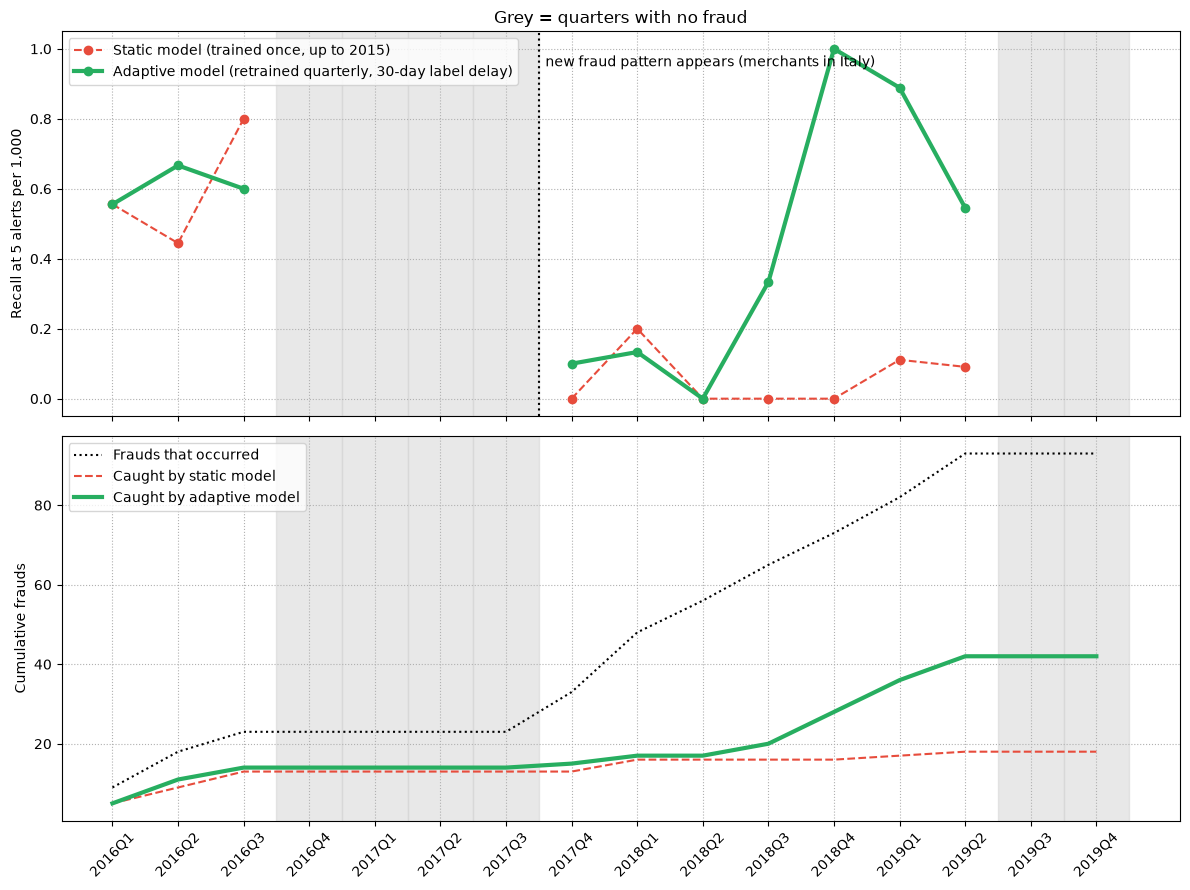

In [13]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

print("--- Starting Stream Replay: Static vs Adaptive (2016-2019) ---")

static_xgb = xgb.XGBClassifier(scale_pos_weight=scale_weight, random_state=SEED, eval_metric='aucpr')
static_xgb.fit(X_train, y_train)

adaptive_xgb = xgb.XGBClassifier(scale_pos_weight=scale_weight, random_state=SEED, eval_metric='aucpr')
adaptive_xgb.fit(X_train, y_train)

df_stream = df[(df['Year'] >= 2016) & (df['Year'] <= 2019)].copy()
df_stream['quarter'] = df_stream['ts'].dt.to_period('Q')
quarters = df_stream['quarter'].sort_values().unique()

results = []

for q in quarters:
    q_mask = df_stream['quarter'] == q
    X_test_q = df_stream.loc[q_mask, FEATURE_COLUMNS]
    y_test_q = df_stream.loc[q_mask, 'is_fraud']
    
    if len(y_test_q) == 0:
        continue
        
    # Static Model
    st_probs = static_xgb.predict_proba(X_test_q)[:, 1]
    st_thr = threshold_for_budget(st_probs, alerts_per_1000=5)
    st_preds = (st_probs >= st_thr).astype(int)
    _, st_fp, st_fn, st_tp = confusion_matrix(y_test_q, st_preds, labels=[0, 1]).ravel()
    st_recall = st_tp / (st_tp + st_fn) if (st_tp + st_fn) > 0 else np.nan
    
    # Adaptive Model
    ad_probs = adaptive_xgb.predict_proba(X_test_q)[:, 1]
    ad_thr = threshold_for_budget(ad_probs, alerts_per_1000=5)
    ad_preds = (ad_probs >= ad_thr).astype(int)
    _, ad_fp, ad_fn, ad_tp = confusion_matrix(y_test_q, ad_preds, labels=[0, 1]).ravel()
    ad_recall = ad_tp / (ad_tp + ad_fn) if (ad_tp + ad_fn) > 0 else np.nan
    
    results.append({
        'Quarter': str(q),
        'Static_Recall': st_recall,
        'Static_FP': st_fp,
        'Adaptive_Recall': ad_recall,
        'Adaptive_FP': ad_fp,
        'Frauds': int(y_test_q.sum())
    })

    # Retrain Adaptive model with label delay lag
    visible_end_time = q.end_time - pd.Timedelta(days=30)
    visible_start_time = visible_end_time - pd.DateOffset(years=2)
    
    train_mask = (df['ts'] >= visible_start_time) & (df['ts'] < visible_end_time)
    X_adapt_train = df.loc[train_mask, FEATURE_COLUMNS]
    y_adapt_train = df.loc[train_mask, 'is_fraud']
    
    if len(y_adapt_train) > 0 and y_adapt_train.sum() > 0:
        scale_w = (y_adapt_train == 0).sum() / y_adapt_train.sum()
        adaptive_xgb.set_params(scale_pos_weight=scale_w)
        adaptive_xgb.fit(X_adapt_train, y_adapt_train)

replay_df = pd.DataFrame(results)
print("\n--- 📊 Stream Replay Results ---")
print(replay_df.to_string(index=False))

# Chart rendering
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
x = np.arange(len(replay_df))
for i, n in enumerate(replay_df['Frauds']):
    if n == 0:
        ax1.axvspan(i - 0.5, i + 0.5, color='lightgrey', alpha=0.5)
        ax2.axvspan(i - 0.5, i + 0.5, color='lightgrey', alpha=0.5)

ax1.plot(x, replay_df['Static_Recall'], 'o--', color='#e74c3c', label='Static model (trained once, up to 2015)')
ax1.plot(x, replay_df['Adaptive_Recall'], 'o-', color='#27ae60', linewidth=3, label='Adaptive model (retrained quarterly, 30-day label delay)')
ax1.axvline(replay_df.index[replay_df['Quarter'] == '2017Q4'][0] - 0.5, color='black', linestyle=':')
ax1.text(replay_df.index[replay_df['Quarter'] == '2017Q4'][0] - 0.4, 0.95, 'new fraud pattern appears (merchants in Italy)', fontsize=10)
ax1.set_ylabel('Recall at 5 alerts per 1,000')
ax1.set_ylim(-0.05, 1.05)
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':')
ax1.set_title('Grey = quarters with no fraud')

caught_s = (replay_df['Static_Recall'].fillna(0) * replay_df['Frauds']).cumsum()
caught_a = (replay_df['Adaptive_Recall'].fillna(0) * replay_df['Frauds']).cumsum()
ax2.plot(x, replay_df['Frauds'].cumsum(), 'k:', label='Frauds that occurred')
ax2.plot(x, caught_s, '--', color='#e74c3c', label='Caught by static model')
ax2.plot(x, caught_a, '-', color='#27ae60', linewidth=3, label='Caught by adaptive model')
ax2.set_ylabel('Cumulative frauds')
ax2.legend(loc='upper left')
ax2.grid(True, linestyle=':')
ax2.set_xticks(x)
ax2.set_xticklabels(replay_df['Quarter'], rotation=45)
plt.tight_layout()
plt.show()

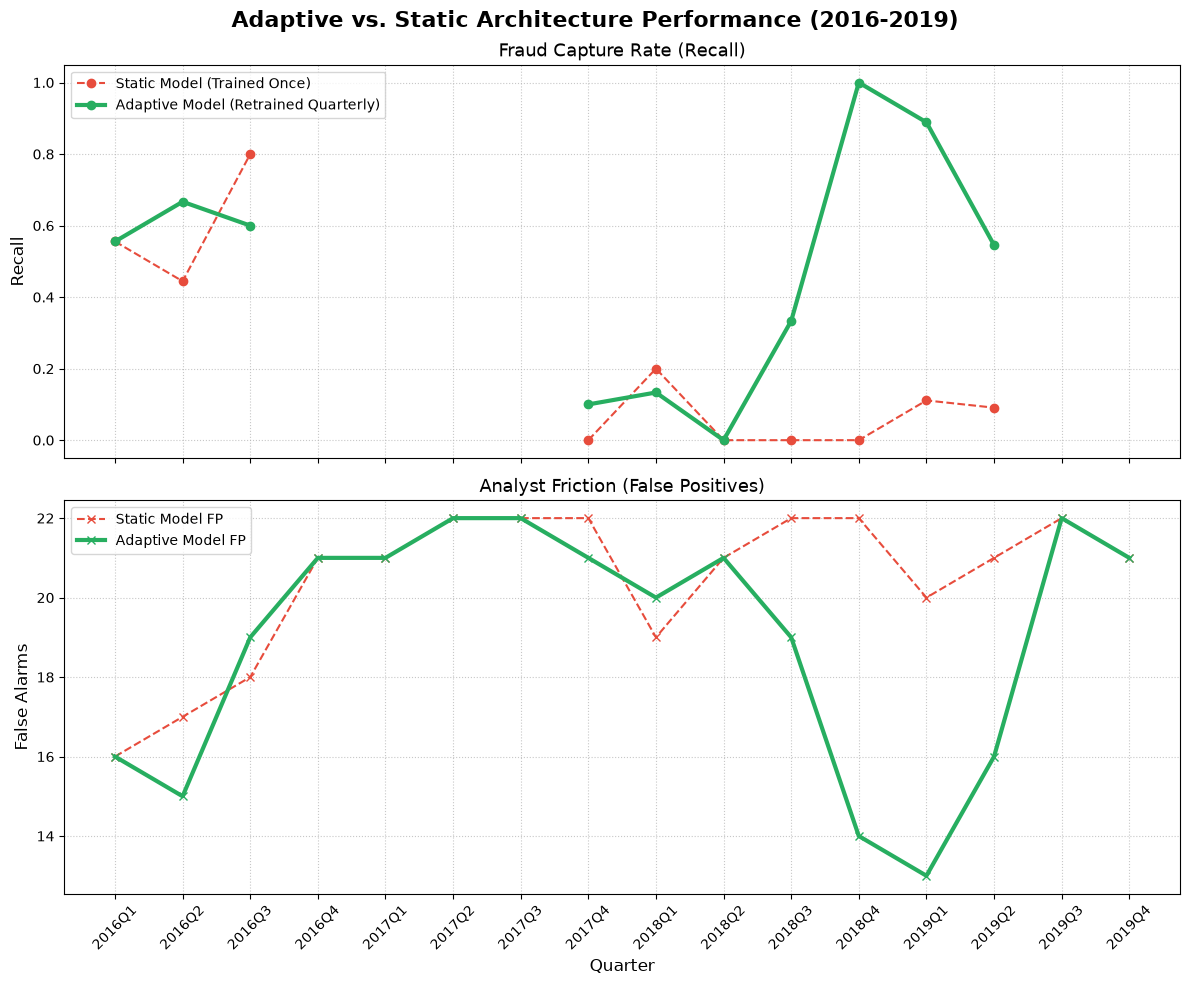

✅ Phase 3 Complete! Key pitch chart saved to: docs/adaptive-chart.png


In [14]:
import matplotlib.pyplot as plt
import os

# 1. Ensure the required docs directory exists
os.makedirs('docs', exist_ok=True)

# 2. Set up the figure with two subplots (Recall on top, False Alarms on bottom)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
fig.suptitle('Adaptive vs. Static Architecture Performance (2016-2019)', fontsize=16, fontweight='bold', y=0.98)

# 3. Plot Recall (Higher is better)
ax1.plot(replay_df['Quarter'], replay_df['Static_Recall'], marker='o', linestyle='--', color='#e74c3c', label='Static Model (Trained Once)')
ax1.plot(replay_df['Quarter'], replay_df['Adaptive_Recall'], marker='o', linestyle='-', color='#27ae60', linewidth=3, label='Adaptive Model (Retrained Quarterly)')
ax1.set_title('Fraud Capture Rate (Recall)', fontsize=13)
ax1.set_ylabel('Recall', fontsize=12)
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend(loc='upper left')

# 4. Plot False Alarms (Lower is better)
ax2.plot(replay_df['Quarter'], replay_df['Static_FP'], marker='x', linestyle='--', color='#e74c3c', label='Static Model FP')
ax2.plot(replay_df['Quarter'], replay_df['Adaptive_FP'], marker='x', linestyle='-', color='#27ae60', linewidth=3, label='Adaptive Model FP')
ax2.set_title('Analyst Friction (False Positives)', fontsize=13)
ax2.set_ylabel('False Alarms', fontsize=12)
ax2.set_xlabel('Quarter', fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend(loc='upper left')

# 5. Formatting
plt.xticks(rotation=45)
plt.tight_layout()

# 6. Save directly to the required datathon path
chart_path = 'docs/adaptive-chart.png'
plt.savefig(chart_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Phase 3 Complete! Key pitch chart saved to: {chart_path}")

In [15]:
import json, joblib, os

os.makedirs('/home/ibm-user/shared/models', exist_ok=True)
M = '/home/ibm-user/shared/models/'

xgb_model.save_model(M + 'xgb.json')
model.save(M + 'tf_dense.keras')
lstm_model.save(M + 'lstm.keras')
joblib.dump(scaler, M + 'scaler.joblib')

json.dump({
    'feature_columns': FEATURE_COLUMNS, 
    'nn_features': NN_FEATURES,
    'blend_weights': [float(w) for w in best_w],
    'red_thr': float(red_thr), 
    'yellow_thr': float(yellow_thr),
    'tf_thr': float(tf_thr), 
    'lstm_thr': float(lstm_thr),
    'top_mccs': [int(m) for m in top_mccs], 
    'seq_len': SEQ_LEN,
}, open(M + 'config.json', 'w'), indent=2)

del X_all_seq   # frees ~600 MB
print("Successfully saved all production artifacts to:", M)

Successfully saved all production artifacts to: /home/ibm-user/shared/models/
